# Práctica Evaluativa 1 — Análisis exploratorio y estadístico de datos

**Estudiante:** Alexander Mejia Ospina  
**Asignatura:** Analítica de Datos  
**Programa:** Ingeniería de Software — Universidad Cooperativa de Colombia  
**Docente:** Luis Miguel Gómez Meneses  
**Fecha de entrega:** 11 de septiembre de 2026  
**Dataset:** Retail Sales Dataset (Kaggle)

---

En este notebook se hace el análisis completo del dataset asignado, siguiendo el mismo orden que trabajamos en los laboratorios:

1. Comprensión inicial de los datos
2. Diagnóstico de calidad
3. Preparación de los datos
4. Análisis exploratorio y descriptivo
5. Detección e investigación de valores atípicos
6. Relaciones, correlación y significancia estadística
7. Conclusiones

La idea no es solo correr código, sino explicar cada decisión y qué significan los resultados.

## 0. Librerías

Se usan las mismas librerías de los laboratorios:

- `pandas` para cargar y manipular los datos;
- `matplotlib` y `seaborn` para las gráficas;
- `scipy.stats`: se usan `pearsonr()` y `spearmanr()` para calcular los coeficientes de correlación junto con su p-value.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# 1. Comprensión inicial de los datos

## 1.1 Contexto y fuente del dataset

El dataset es el **Retail Sales Dataset**, publicado en Kaggle:  
https://www.kaggle.com/datasets/mohammadtalib786/retail-sales-dataset

Según su descripción en Kaggle, es un conjunto de datos **ficticio (sintético)** que simula las ventas de un comercio minorista. Cada fila es una transacción y trae información de la fecha, el cliente (género y edad), la categoría del producto, la cantidad comprada, el precio por unidad y el monto total.

## 1.2 Carga de los datos

> **Nota:** antes de ejecutar, subir el archivo `retail_sales_dataset.csv` al panel de *Archivos* de Colab (queda en `/content/`). Si se prefiere trabajar desde Google Drive, se pueden descomentar las líneas del `drive.mount` y cambiar la ruta.

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

ruta = "/content/retail_sales_dataset.csv"
df = pd.read_csv(ruta)
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## 1.3 Dimensiones del dataset

In [ ]:
print("Dimensiones del dataset:", df.shape)
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

Dimensiones del dataset: (1000, 9)
Filas: 1000
Columnas: 9


## 1.4 Variables disponibles

In [ ]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')

| Variable | Qué representa |
|---|---|
| `Transaction ID` | Número que identifica cada transacción |
| `Date` | Fecha en la que se hizo la compra |
| `Customer ID` | Código del cliente (CUST001, CUST002, …) |
| `Gender` | Género del cliente (Male / Female) |
| `Age` | Edad del cliente en años |
| `Product Category` | Categoría del producto comprado |
| `Quantity` | Cantidad de unidades compradas en la transacción |
| `Price per Unit` | Precio de cada unidad |
| `Total Amount` | Valor total de la transacción |

## 1.5 Tipos de datos

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [ ]:
df.dtypes

,0
Transaction ID,int64
Date,object
Customer ID,object
Gender,object
Age,int64
Product Category,object
Quantity,int64
Price per Unit,int64
Total Amount,int64


## 1.6 Variables numéricas y categóricas

Primero veamos cómo las clasifica pandas según el tipo de dato, y cuántos valores distintos tiene cada columna. Esto último ayuda a saber si una columna es un identificador, una categoría o una medida.

In [ ]:
numericas_pandas = df.select_dtypes(include="number").columns.tolist()
no_numericas_pandas = df.select_dtypes(exclude="number").columns.tolist()

print("Numéricas según pandas:   ", numericas_pandas)
print("No numéricas según pandas:", no_numericas_pandas)

Numéricas según pandas:    ['Transaction ID', 'Age', 'Quantity', 'Price per Unit', 'Total Amount']
No numéricas según pandas: ['Date', 'Customer ID', 'Gender', 'Product Category']


In [ ]:
df.nunique()

,0
Transaction ID,1000
Date,345
Customer ID,1000
Gender,2
Age,47
Product Category,3
Quantity,4
Price per Unit,5
Total Amount,18


### Resumen de la inspección inicial

- El dataset tiene **1.000 filas** (transacciones) y **9 columnas**.
- Pandas reconoce 5 columnas como numéricas (`int64`) y 4 como texto.
- Pero no todo lo que pandas marca como número es una variable numérica para el análisis:
  - `Transaction ID` es un número, pero es un **identificador**: no tiene sentido sacarle promedio. Tiene 1.000 valores distintos, uno por fila.
  - `Customer ID` también es un identificador (1.000 valores distintos, o sea que **cada cliente aparece una sola vez**).
- `Date` quedó cargada como **texto**, aunque en realidad es una fecha. Hay que corregirla en la preparación.

Clasificación final de las variables:

| Tipo | Variables |
|---|---|
| **Numéricas (para analizar)** | `Age`, `Quantity`, `Price per Unit`, `Total Amount` |
| **Categóricas** | `Gender` (2 valores), `Product Category` (3 valores) |
| **Temporal** | `Date` |
| **Identificadores** | `Transaction ID`, `Customer ID` |

Un detalle a tener en cuenta: `Quantity` solo toma 4 valores y `Price per Unit` solo 5, así que aunque son numéricas, son **discretas** y con pocos valores posibles.

# 2. Diagnóstico de calidad de los datos

En esta parte solo se **detecta, cuantifica e interpreta**. No se corrige nada todavía (igual que en el Laboratorio 2).

## 2.1 Perfil de las variables numéricas

In [ ]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


A primera vista los mínimos y máximos se ven razonables: edades entre 18 y 64 años, cantidades de 1 a 4 unidades, precios entre 25 y 500 y montos entre 25 y 2.000. Todas las columnas tienen `count = 1000`, lo que ya sugiere que no hay faltantes. En `Price per Unit` y `Total Amount` la media es bastante mayor que la mediana, señal de distribuciones sesgadas a la derecha.

## 2.2 Valores faltantes

In [ ]:
faltantes = pd.DataFrame({
    "cantidad": df.isnull().sum(),
    "porcentaje": (df.isnull().sum() / len(df) * 100).round(2)
})
faltantes

,cantidad,porcentaje
Transaction ID,0,0.0
Date,0,0.0
Customer ID,0,0.0
Gender,0,0.0
Age,0,0.0
Product Category,0,0.0
Quantity,0,0.0
Price per Unit,0,0.0
Total Amount,0,0.0


## 2.3 Registros duplicados

Se revisan tres cosas:

1. Filas exactamente iguales.
2. Filas iguales si se ignora el `Transaction ID` (por si la misma compra se registró dos veces con distinto número).
3. Que los identificadores no se repitan.

In [ ]:
print("Filas exactamente duplicadas:", df.duplicated().sum())
print("Duplicados ignorando Transaction ID:", df.drop(columns="Transaction ID").duplicated().sum())
print("¿Transaction ID es único?:", df["Transaction ID"].is_unique)
print("¿Customer ID es único?:", df["Customer ID"].is_unique)

Filas exactamente duplicadas: 0
Duplicados ignorando Transaction ID: 0
¿Transaction ID es único?: True
¿Customer ID es único?: True


## 2.4 Tipos de datos

Revisamos cómo quedó cargada la fecha.

In [ ]:
print("Tipo de la columna Date:", df["Date"].dtype)
print("Tipo de un valor de Date:", type(df["Date"][0]))
print("Ejemplo:", df["Date"][0])

Tipo de la columna Date: object
Tipo de un valor de Date: <class 'str'>
Ejemplo: 2023-11-24


También se revisa si todas las fechas se pueden convertir sin errores y cuál es el periodo que cubren. Esta conversión es **temporal**, solo para diagnosticar (no se guarda en `df`).

In [ ]:
fechas = pd.to_datetime(df["Date"], errors="coerce")

print("Fechas que no se pudieron convertir:", fechas.isnull().sum())
print("Fecha mínima:", fechas.min().date())
print("Fecha máxima:", fechas.max().date())
print()
print("Transacciones por año:")
print(fechas.dt.year.value_counts().sort_index())

Fechas que no se pudieron convertir: 0
Fecha mínima: 2023-01-01
Fecha máxima: 2024-01-01

Transacciones por año:
Date
2023    998
2024      2
Name: count, dtype: int64


## 2.5 Inconsistencias en variables categóricas

Se revisan las categorías de `Gender` y `Product Category`. Para detectar variantes del tipo "medellin" / "Medellín" / "MEDELLÍN", se compara cuántos valores únicos hay antes y después de quitar espacios y pasar todo a minúsculas. Si el número baja, es porque hay categorías escritas de forma diferente.

In [ ]:
df["Gender"].value_counts()

,count
Gender,
Female,510
Male,490


In [ ]:
df["Product Category"].value_counts()

,count
Product Category,
Clothing,351
Electronics,342
Beauty,307


In [ ]:
for columna in ["Gender", "Product Category"]:
    originales = df[columna].nunique()
    normalizados = df[columna].str.strip().str.lower().nunique()
    print(f"{columna}: {originales} valores únicos | después de strip + lower: {normalizados}")

Gender: 2 valores únicos | después de strip + lower: 2
Product Category: 3 valores únicos | después de strip + lower: 3


## 2.6 Rangos y valores de las variables numéricas

Además de ver mínimos y máximos, se verifica que no haya valores imposibles (edades negativas o muy altas, cantidades o precios en cero o negativos).

In [ ]:
print("Edades fuera de 0 a 100:", ((df["Age"] < 0) | (df["Age"] > 100)).sum())
print("Cantidades <= 0:", (df["Quantity"] <= 0).sum())
print("Precios <= 0:", (df["Price per Unit"] <= 0).sum())
print("Montos totales <= 0:", (df["Total Amount"] <= 0).sum())

Edades fuera de 0 a 100: 0
Cantidades <= 0: 0
Precios <= 0: 0
Montos totales <= 0: 0


In [ ]:
df["Quantity"].unique()

array([3, 2, 1, 4])

In [ ]:
df["Price per Unit"].unique()

array([ 50, 500,  30,  25, 300])

### Consistencia entre variables

Por lógica, el monto total de una transacción debería ser la cantidad por el precio unitario:

$$
\text{Total Amount} = \text{Quantity} \times \text{Price per Unit}
$$

Se verifica si esto se cumple en todas las filas.

In [ ]:
inconsistentes = df["Total Amount"] != df["Quantity"] * df["Price per Unit"]
print("Filas donde Total Amount ≠ Quantity × Price per Unit:", inconsistentes.sum())

Filas donde Total Amount ≠ Quantity × Price per Unit: 0


Por último, se revisa cómo se reparten los precios por categoría, para ver si tienen sentido con el tipo de producto.

In [ ]:
pd.crosstab(df["Product Category"], df["Price per Unit"])

Price per Unit,25,30,50,300,500
Product Category,,,,,
Beauty,63,56,67,53,68
Clothing,75,65,75,72,64
Electronics,72,62,69,72,67


## 2.7 Registro de hallazgos

| Aspecto revisado | Hallazgo | Evidencia | ¿Requiere tratamiento? |
|---|---|---|---|
| Valores faltantes | No hay | 0 faltantes en las 9 columnas | No |
| Duplicados | No hay | 0 filas duplicadas, 0 duplicadas sin contar el ID; IDs únicos | No |
| Tipo de `Date` | Está como texto | Se leyó como texto (`str`/`object`), no como fecha | **Sí** |
| Tipo de `Transaction ID` | Es un identificador guardado como número | `int64`, 1.000 valores distintos | **Sí** (recomendable) |
| Categorías (`Gender`, `Product Category`) | Sin inconsistencias | Mismo número de valores únicos antes y después de normalizar | No |
| Rangos numéricos | Plausibles | Sin edades, cantidades, precios o montos imposibles | No |
| Consistencia `Total Amount` | Se cumple la fórmula | 0 filas inconsistentes | No |
| Fechas de 2024 | 2 transacciones del 1 de enero de 2024 | Casi todo es 2023 | No (se conservan, pero se tienen en cuenta en el análisis por mes) |
| Precios por categoría | Las 3 categorías tienen exactamente los mismos 5 precios | Tabla cruzada anterior | No se puede corregir (es propio de un dataset sintético); se deja como limitación |
| `Customer ID` | Cada cliente aparece una sola vez | 1.000 valores únicos | No (pero no se puede analizar clientes que repiten compra) |

**Conclusión del diagnóstico:** el dataset está en muy buen estado. Los únicos problemas que necesitan tratamiento antes de continuar son de **tipo de dato** (`Date` y `Transaction ID`). Lo demás se verificó y no presenta problemas, y eso también es un resultado válido del diagnóstico.

# 3. Preparación de los datos

Se sigue el mismo proceso del Laboratorio 3:

**problema detectado → decisión → transformación → verificación**

Solo se aplican las transformaciones que el diagnóstico mostró necesarias.

## 3.1 Corrección del tipo de `Date`

**Problema:** `Date` quedó como texto. Así no se puede ordenar bien por fecha ni agrupar por mes.  
**Decisión:** convertirla a tipo fecha con `pd.to_datetime()`. En el diagnóstico se vio que todas las fechas se convierten sin errores, así que no se pierde ningún dato.

### Antes

In [ ]:
print("Tipo antes:", df["Date"].dtype)

Tipo antes: object


### Transformación

In [ ]:
df["Date"] = pd.to_datetime(df["Date"])

### Verificación

In [ ]:
print("Tipo después:", df["Date"].dtype)
print("Ejemplo:", df["Date"][0])
print("Fechas nulas:", df["Date"].isnull().sum())

Tipo después: datetime64[ns]
Ejemplo: 2023-11-24 00:00:00
Fechas nulas: 0


## 3.2 `Transaction ID` como identificador

**Problema:** `Transaction ID` está como número entero, entonces pandas lo mete en `describe()` y en los cálculos numéricos, cuando en realidad es solo un código.  
**Decisión:** convertirlo a texto (`str`). No se pierde información, solo se evita que se use por error como una medida (por ejemplo, sacar el "promedio del ID" no significa nada).

### Antes

In [ ]:
print("Tipo antes:", df["Transaction ID"].dtype)

Tipo antes: int64


### Transformación

In [ ]:
df["Transaction ID"] = df["Transaction ID"].astype(str)

### Verificación

In [ ]:
print("Tipo después:", df["Transaction ID"].dtype)
print("Valores únicos:", df["Transaction ID"].nunique())
print("Columnas numéricas ahora:", df.select_dtypes(include="number").columns.tolist())

Tipo después: object
Valores únicos: 1000
Columnas numéricas ahora: ['Age', 'Quantity', 'Price per Unit', 'Total Amount']


## 3.3 Procedimientos que NO se aplicaron (y por qué)

Como dice la guía, no hay que aplicar todo por aplicar. Estas son las decisiones:

- **Valores faltantes:** no hay, así que no se imputa nada.
- **Duplicados:** no hay filas duplicadas ni compras repetidas con distinto ID, así que no se usa `drop_duplicates()`.
- **Normalización de categorías:** `Gender` y `Product Category` ya están escritas de forma uniforme (no cambió el número de categorías al normalizar). No se transforman.
- **Reconstrucción de información:** no hace falta, porque `Total Amount` coincide con `Quantity × Price per Unit` en las 1.000 filas y no hay montos faltantes que reconstruir.
- **Transacciones del 1 de enero de 2024:** son fechas válidas y los demás valores de esas filas son normales, así que **se conservan**. Solo hay que tener presente que enero de 2024 no es un mes completo cuando se analicen las ventas por mes.

Se hace de nuevo la verificación rápida de duplicados para dejarlo evidenciado en esta etapa:

In [ ]:
print("Duplicados:", df.duplicated().sum())

Duplicados: 0


## 3.4 Verificación final del dataset preparado

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   object        
 1   Date              1000 non-null   datetime64[ns]
 2   Customer ID       1000 non-null   object        
 3   Gender            1000 non-null   object        
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   object        
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
dtypes: datetime64[ns](1), int64(4), object(4)
memory usage: 70.4+ KB


In [ ]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])
print("Valores faltantes:", df.isnull().sum().sum())
print("Duplicados:", df.duplicated().sum())
print("Tipo de Date:", df["Date"].dtype)
print("Tipo de Transaction ID:", df["Transaction ID"].dtype)
print("Categorías de producto:", df["Product Category"].nunique())
print("Filas inconsistentes en Total Amount:",
      (df["Total Amount"] != df["Quantity"] * df["Price per Unit"]).sum())

Filas: 1000
Columnas: 9
Valores faltantes: 0
Duplicados: 0
Tipo de Date: datetime64[ns]
Tipo de Transaction ID: object
Categorías de producto: 3
Filas inconsistentes en Total Amount: 0


Las transformaciones quedaron bien: `Date` ya es fecha, `Transaction ID` ya no se trata como número, y se mantienen las 1.000 filas y 9 columnas sin faltantes ni duplicados.

## 3.5 Guardar el dataset preparado

No se sobrescribe el archivo original. Se guarda una copia preparada para mantener la trazabilidad (igual que en el Laboratorio 3).

In [ ]:
df.to_csv("retail_sales_preparado.csv", index=False)
print("Archivo guardado: retail_sales_preparado.csv")

Archivo guardado: retail_sales_preparado.csv


# 4. Análisis exploratorio y descriptivo

## 4.1 Variables seleccionadas

- **`Total Amount`** (variable principal): es el valor de cada venta, lo más importante para el negocio.
- **`Price per Unit`** y **`Quantity`**: son las que forman el monto total.
- **`Age`**: describe al cliente y sirve para ver si la edad tiene que ver con cuánto gasta.
- **`Product Category`** y **`Gender`**: para comparar grupos.

## 4.2 Medidas de posición y dispersión

Se calculan todas las medidas pedidas para las cuatro variables numéricas en una sola tabla.

In [ ]:
variables = ["Age", "Quantity", "Price per Unit", "Total Amount"]

medidas = pd.DataFrame({
    "media": df[variables].mean(),
    "mediana": df[variables].median(),
    "mínimo": df[variables].min(),
    "máximo": df[variables].max(),
    "Q1": df[variables].quantile(0.25),
    "Q2": df[variables].quantile(0.50),
    "Q3": df[variables].quantile(0.75),
    "desv_estándar": df[variables].std(),
})
medidas["rango"] = medidas["máximo"] - medidas["mínimo"]
medidas["IQR"] = medidas["Q3"] - medidas["Q1"]

medidas.round(2)

,media,mediana,mínimo,máximo,Q1,Q2,Q3,desv_estándar,rango,IQR
Age,41.39,42.0,18,64,29.0,42.0,53.0,13.68,46,24.0
Quantity,2.51,3.0,1,4,1.0,3.0,4.0,1.13,3,3.0
Price per Unit,179.89,50.0,25,500,30.0,50.0,300.0,189.68,475,270.0
Total Amount,456.00,135.0,25,2000,60.0,135.0,900.0,560.00,1975,840.0


Ahora se detalla la variable principal, `Total Amount`, como en el Laboratorio 5:

In [ ]:
monto = df["Total Amount"]

print(f"Media:               {monto.mean():,.2f}")
print(f"Mediana:             {monto.median():,.2f}")
print(f"Mínimo:              {monto.min():,.2f}")
print(f"Máximo:              {monto.max():,.2f}")
print(f"Rango:               {monto.max() - monto.min():,.2f}")
print(f"Q1 (25%):            {monto.quantile(0.25):,.2f}")
print(f"Q2 (50%):            {monto.quantile(0.50):,.2f}")
print(f"Q3 (75%):            {monto.quantile(0.75):,.2f}")
print(f"IQR:                 {monto.quantile(0.75) - monto.quantile(0.25):,.2f}")
print(f"Desviación estándar: {monto.std():,.2f}")

Media:               456.00
Mediana:             135.00
Mínimo:              25.00
Máximo:              2,000.00
Rango:               1,975.00
Q1 (25%):            60.00
Q2 (50%):            135.00
Q3 (75%):            900.00
IQR:                 840.00
Desviación estándar: 560.00


### Interpretación

**`Total Amount`**
- La **media es 456** y la **mediana 135**. La media es más de tres veces la mediana, lo que indica que hay transacciones de valor alto que "jalan" el promedio hacia arriba. La mitad de las compras son de 135 o menos, así que la **mediana representa mejor una compra típica**.
- El **rango es 1.975** (de 25 a 2.000), o sea que hay mucha distancia entre la compra más barata y la más cara.
- Los cuartiles muestran que el 25 % de las compras vale 60 o menos, y el 75 % vale 900 o menos. El **IQR es 840**: el 50 % central de las compras está entre 60 y 900.
- La **desviación estándar (560)** es incluso mayor que la media, así que los montos son muy dispersos: hay muchas compras pequeñas y otras bastante grandes, casi sin punto medio.

**`Price per Unit`**
- Media de 179,89 y mediana de 50. Pasa lo mismo que con el monto: la mayoría de productos son baratos (25, 30 o 50) y unos pocos muy caros (300 y 500) suben la media. El IQR (270) es grande porque Q1 = 30 y Q3 = 300 caen en precios muy diferentes.

**`Quantity`**
- Media de 2,51 y mediana de 3; va de 1 a 4 unidades. Es una variable con muy poca variación (desviación de 1,13), y la media y la mediana están cerca.

**`Age`**
- Media de 41,39 años y mediana de 42, casi iguales, así que la edad tiene una distribución bastante **simétrica**. Los clientes van de 18 a 64 años y el 50 % central está entre 29 y 53 años (IQR = 24).

## 4.3 Distribución de las variables numéricas (histogramas)

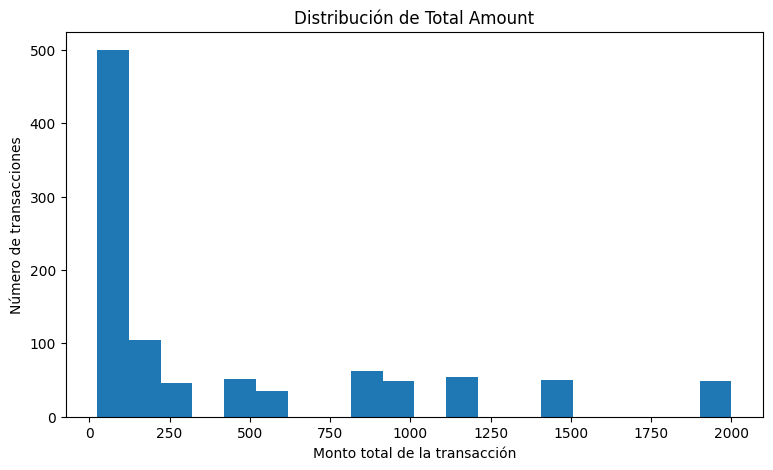

In [ ]:
plt.figure(figsize=(9, 5))
plt.hist(
    df["Total Amount"],
    bins=20
)
plt.xlabel("Monto total de la transacción")
plt.ylabel("Número de transacciones")
plt.title("Distribución de Total Amount")
plt.show()

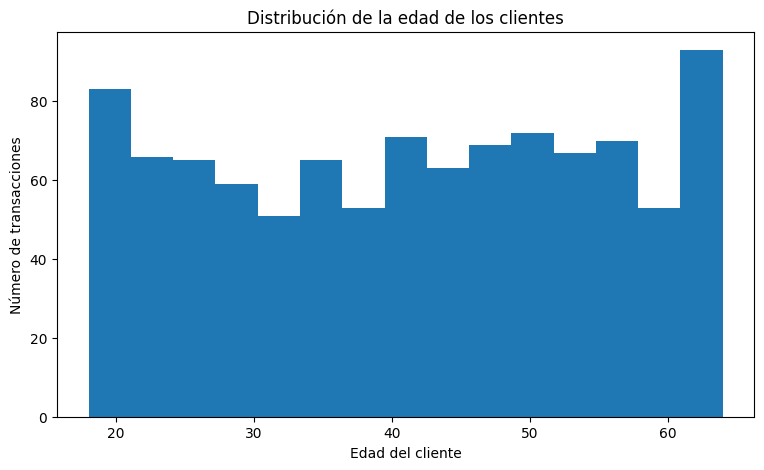

In [ ]:
plt.figure(figsize=(9, 5))
plt.hist(
    df["Age"],
    bins=15
)
plt.xlabel("Edad del cliente")
plt.ylabel("Número de transacciones")
plt.title("Distribución de la edad de los clientes")
plt.show()

`Quantity` y `Price per Unit` solo tienen 4 y 5 valores posibles, así que en vez de histograma se usa un gráfico de barras con la frecuencia de cada valor.

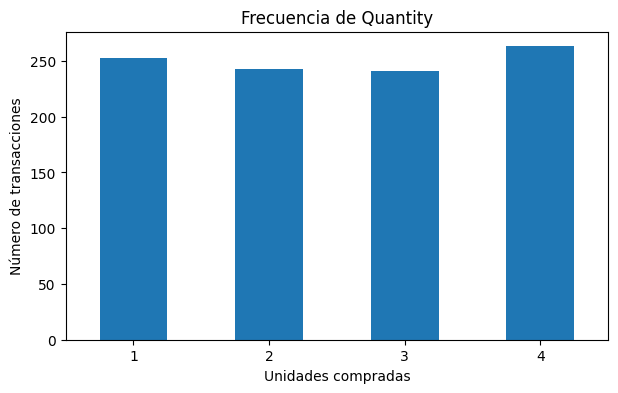

In [ ]:
frecuencia_cantidad = df["Quantity"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
frecuencia_cantidad.plot(kind="bar")
plt.xlabel("Unidades compradas")
plt.ylabel("Número de transacciones")
plt.title("Frecuencia de Quantity")
plt.xticks(rotation=0)
plt.show()

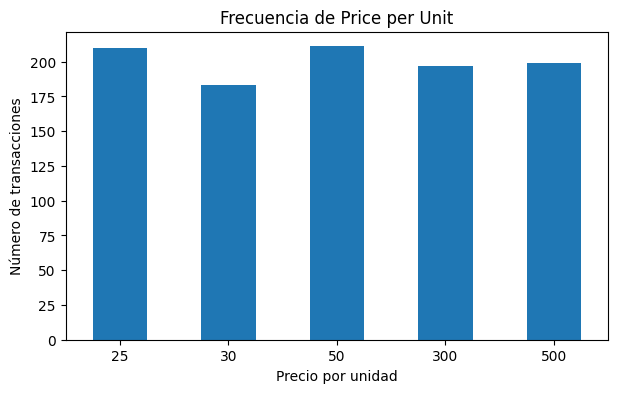

In [ ]:
frecuencia_precio = df["Price per Unit"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
frecuencia_precio.plot(kind="bar")
plt.xlabel("Precio por unidad")
plt.ylabel("Número de transacciones")
plt.title("Frecuencia de Price per Unit")
plt.xticks(rotation=0)
plt.show()

### Interpretación

- **`Total Amount`**: la distribución es **asimétrica a la derecha**. La mayoría de las transacciones se concentran en valores bajos (menos de 500) y luego aparecen grupos de compras de 900, 1.000, 1.200, 1.500 y 2.000. Esto confirma por qué la media (456) queda muy por encima de la mediana (135).
- **`Age`**: no tiene una forma de campana marcada; las edades están repartidas de forma bastante pareja entre 18 y 64 años (distribución casi uniforme y simétrica).
- **`Quantity`**: las cuatro cantidades (1, 2, 3 y 4) aparecen con frecuencias parecidas.
- **`Price per Unit`**: los cinco precios también tienen frecuencias similares (alrededor de 200 transacciones cada uno). Como tres de los cinco precios son bajos (25, 30, 50) y dos son altos (300, 500), la media se sesga hacia arriba.

## 4.4 Boxplots de las variables numéricas

Cada variable tiene su propia escala, por eso se grafican por separado.

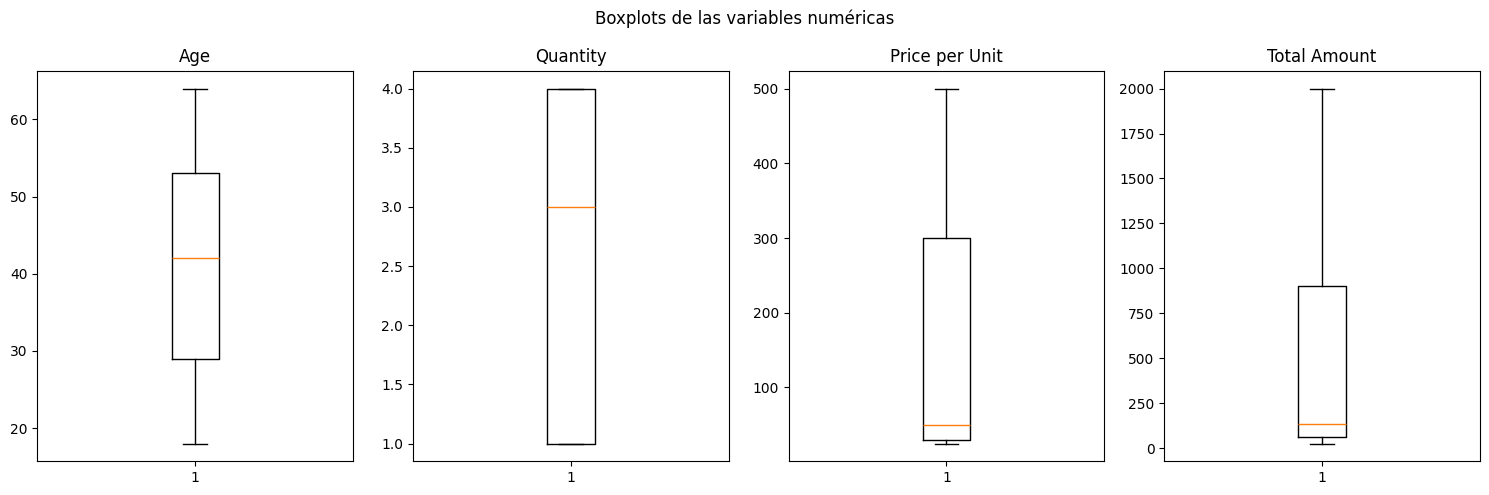

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(15, 5))

axes[0].boxplot(df["Age"])
axes[0].set_title("Age")

axes[1].boxplot(df["Quantity"])
axes[1].set_title("Quantity")

axes[2].boxplot(df["Price per Unit"])
axes[2].set_title("Price per Unit")

axes[3].boxplot(df["Total Amount"])
axes[3].set_title("Total Amount")

plt.suptitle("Boxplots de las variables numéricas")
plt.tight_layout()
plt.show()

### Interpretación

- En **ninguna** de las cuatro variables aparecen puntos por fuera de los bigotes, lo que ya adelanta que con el criterio del IQR global no habrá valores atípicos (se confirma en la sección 5).
- En **`Total Amount`** y **`Price per Unit`** la mediana está muy pegada a la parte baja de la caja y el bigote superior es largo, otra forma de ver la asimetría a la derecha.
- En **`Age`** la mediana está casi en la mitad de la caja, lo que coincide con una distribución simétrica.

## 4.5 Ventas por categoría de producto

Como en el Laboratorio 4, se calcula para cada categoría: número de transacciones (`count`), promedio (`mean`), mediana (`median`) y total vendido (`sum`).

In [ ]:
ventas_categoria = (
    df.groupby("Product Category")["Total Amount"]
      .agg(["count", "mean", "median", "sum"])
      .sort_values("sum", ascending=False)
)
ventas_categoria.round(2)

,count,mean,median,sum
Product Category,,,,
Electronics,342,458.79,150.0,156905
Clothing,351,443.25,120.0,155580
Beauty,307,467.48,120.0,143515


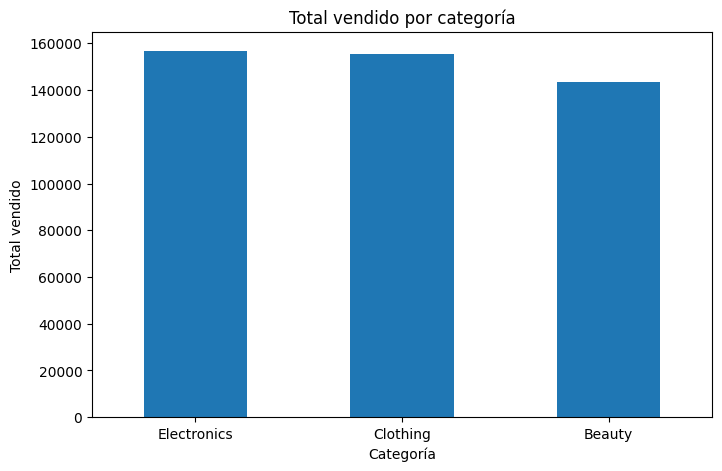

In [ ]:
plt.figure(figsize=(8, 5))
ventas_categoria["sum"].plot(kind="bar")
plt.xlabel("Categoría")
plt.ylabel("Total vendido")
plt.title("Total vendido por categoría")
plt.xticks(rotation=0)
plt.show()

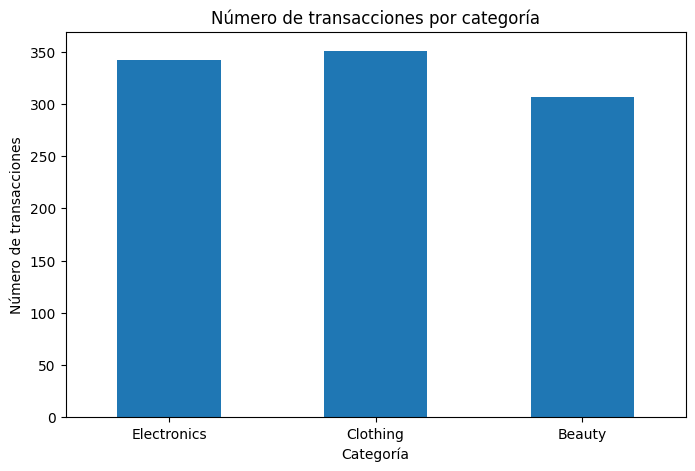

In [ ]:
plt.figure(figsize=(8, 5))
ventas_categoria["count"].plot(kind="bar")
plt.xlabel("Categoría")
plt.ylabel("Número de transacciones")
plt.title("Número de transacciones por categoría")
plt.xticks(rotation=0)
plt.show()

### Interpretación

- **Electronics** es la categoría con **mayor total vendido** (156.905), seguida muy de cerca por **Clothing** (155.580). **Beauty** queda de última (143.515).
- **Clothing** es la que tiene **más transacciones** (351), pero no la que más vende en total.
- **Beauty** tiene menos transacciones (307) pero el **mayor promedio por compra** (467,48).
- Las diferencias entre categorías son **pequeñas**: el total vendido varía menos de un 10 % entre la primera y la última, y los promedios están todos entre 443 y 468. En la mediana, Electronics (150) es algo más alta que Beauty y Clothing (120).
- Igual que en el Laboratorio 4: más transacciones no significa necesariamente más ventas totales.

## 4.6 Ventas por género

In [ ]:
ventas_genero = (
    df.groupby("Gender")["Total Amount"]
      .agg(["count", "mean", "median", "sum"])
)
ventas_genero.round(2)

,count,mean,median,sum
Gender,,,,
Female,510,456.55,150.0,232840
Male,490,455.43,120.0,223160


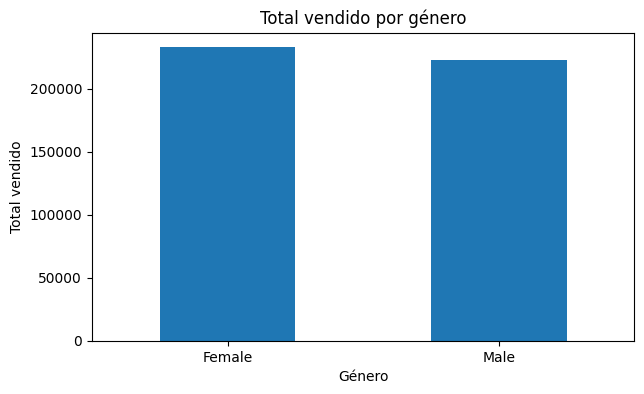

In [ ]:
plt.figure(figsize=(7, 4))
ventas_genero["sum"].plot(kind="bar")
plt.xlabel("Género")
plt.ylabel("Total vendido")
plt.title("Total vendido por género")
plt.xticks(rotation=0)
plt.show()

### Interpretación

Las mujeres (`Female`) hicieron un poco más de compras (510 contra 490) y por eso suman un poco más de ventas (232.840 contra 223.160). Pero el **promedio por compra es prácticamente el mismo** (456,55 contra 455,43). En este dataset el género no marca una diferencia importante en cuánto se gasta por transacción.

## 4.7 Ventas por mes

Se crea una columna auxiliar `Mes` a partir de `Date` para ver el comportamiento en el tiempo. Esto es posible gracias a que `Date` ya se convirtió a fecha en la preparación.

`dt.to_period("M")` toma solo el año y el mes de cada fecha (por ejemplo `2023-05`). Se usa año y mes, y no solo el mes, para que enero de 2023 y enero de 2024 no queden mezclados.

In [ ]:
df["Mes"] = df["Date"].dt.to_period("M").astype(str)

ventas_mes = df.groupby("Mes")["Total Amount"].agg(["count", "sum"])
ventas_mes

,count,sum
Mes,,
2023-01,76,35450
2023-02,85,44060
2023-03,73,28990
2023-04,86,33870
2023-05,105,53150
2023-06,77,36715
2023-07,72,35465
2023-08,94,36960
2023-09,65,23620


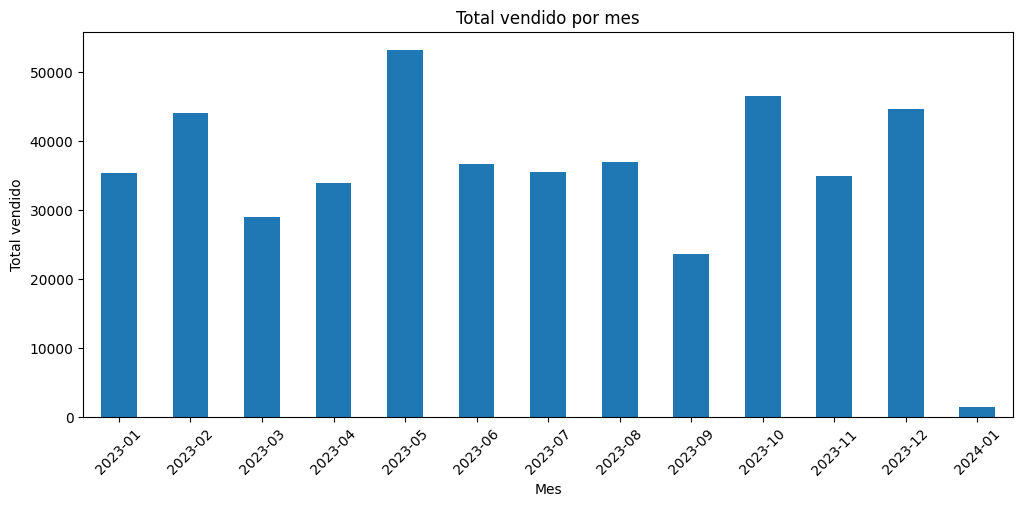

In [ ]:
plt.figure(figsize=(12, 5))
ventas_mes["sum"].plot(kind="bar")
plt.xlabel("Mes")
plt.ylabel("Total vendido")
plt.title("Total vendido por mes")
plt.xticks(rotation=45)
plt.show()

### Interpretación

- **Mayo de 2023** es el mes con más ventas (53.150 y 105 transacciones) y **septiembre de 2023** el más bajo (23.620 y 65 transacciones).
- Las ventas suben y bajan de un mes a otro sin una tendencia clara de crecimiento o caída a lo largo del año.
- **Enero de 2024** aparece con solo 1.530 porque únicamente tiene 2 transacciones (las del 1 de enero). No es un mes comparable con los demás, tal como se anotó en el diagnóstico.

# 5. Detección e investigación de valores atípicos

Se analiza la variable **`Total Amount`**, porque es la variable principal del negocio y la que mostró la distribución más asimétrica.

Se usa el criterio del rango intercuartílico:

$$
IQR = Q_3 - Q_1
$$

$$
L_i = Q_1 - 1.5(IQR) \qquad L_s = Q_3 + 1.5(IQR)
$$

Un valor es **potencialmente atípico** si es menor que $L_i$ o mayor que $L_s$.

## 5.1 Cálculo de los límites

In [ ]:
q1 = df["Total Amount"].quantile(0.25)
q3 = df["Total Amount"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

print(f"Q1:  {q1:,.2f}")
print(f"Q3:  {q3:,.2f}")
print(f"IQR: {iqr:,.2f}")
print(f"Límite inferior (Li): {limite_inferior:,.2f}")
print(f"Límite superior (Ls): {limite_superior:,.2f}")

Q1:  60.00
Q3:  900.00
IQR: 840.00
Límite inferior (Li): -1,200.00
Límite superior (Ls): 2,160.00


- $L_i = 60 - 1.5(840) = -1.200$. Como no existen montos negativos, este límite en la práctica no aplica: ninguna compra puede quedar por debajo.
- $L_s = 900 + 1.5(840) = 2.160$. Una compra sería atípica por arriba si superara 2.160.

## 5.2 Identificación de los posibles atípicos

In [ ]:
atipicos = df[
    (df["Total Amount"] < limite_inferior) |
    (df["Total Amount"] > limite_superior)
]

print("Total de transacciones:", len(df))
print("Transacciones potencialmente atípicas:", len(atipicos))
print(f"Porcentaje: {len(atipicos) / len(df) * 100:.2f}%")
print("Monto máximo registrado:", df["Total Amount"].max())

Total de transacciones: 1000
Transacciones potencialmente atípicas: 0
Porcentaje: 0.00%
Monto máximo registrado: 2000


**No hay valores atípicos** con el criterio IQR: el monto más alto es 2.000 y el límite superior es 2.160.

Para confirmar que esto no es solo en `Total Amount`, se aplica el mismo criterio a las demás variables numéricas:

In [ ]:
columnas_numericas = ["Age", "Quantity", "Price per Unit"]

for columna in columnas_numericas:
    q1_col = df[columna].quantile(0.25)
    q3_col = df[columna].quantile(0.75)
    iqr_col = q3_col - q1_col
    li_col = q1_col - 1.5 * iqr_col
    ls_col = q3_col + 1.5 * iqr_col
    atipicos_col = df[(df[columna] < li_col) | (df[columna] > ls_col)]
    print(f"{columna}: Li = {li_col}, Ls = {ls_col}, mínimo = {df[columna].min()}, máximo = {df[columna].max()}, atípicos = {len(atipicos_col)}")

Age: Li = -7.0, Ls = 89.0, mínimo = 18, máximo = 64, atípicos = 0
Quantity: Li = -3.5, Ls = 8.5, mínimo = 1, máximo = 4, atípicos = 0
Price per Unit: Li = -375.0, Ls = 705.0, mínimo = 25, máximo = 500, atípicos = 0


En ninguna variable hay valores fuera de los límites: en todos los casos el mínimo y el máximo quedan dentro de $[L_i, L_s]$, así que el conteo de atípicos da 0.

## 5.3 Visualización con boxplot

Se dibuja el boxplot de `Total Amount` y se marcan con líneas los límites calculados.

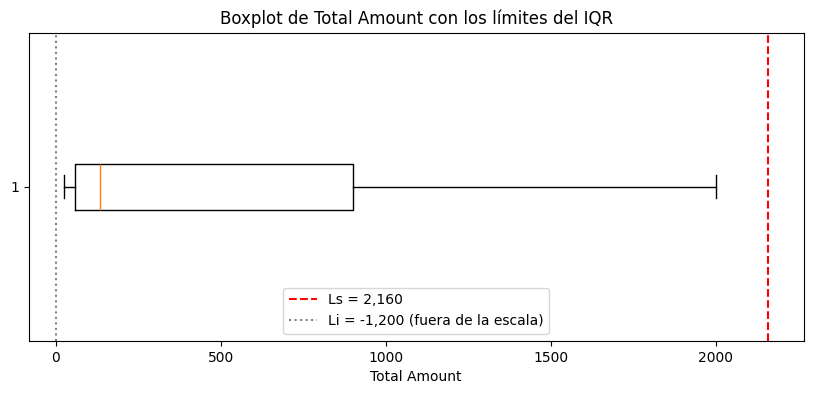

In [ ]:
plt.figure(figsize=(10, 4))
plt.boxplot(df["Total Amount"], vert=False)
plt.axvline(limite_superior, color="red", linestyle="--", label=f"Ls = {limite_superior:,.0f}")
plt.axvline(0, color="gray", linestyle=":", label=f"Li = {limite_inferior:,.0f} (fuera de la escala)")
plt.xlabel("Total Amount")
plt.title("Boxplot de Total Amount con los límites del IQR")
plt.legend()
plt.show()

El boxplot confirma lo calculado: no hay puntos sueltos fuera de los bigotes. El bigote superior llega hasta 2.000 (el valor máximo), que queda por debajo de la línea roja del límite superior. Se ve también la asimetría: la mediana está muy cerca del borde izquierdo de la caja.

## 5.4 Examen de los registros más altos

Aunque no haya atípicos, vale la pena revisar las transacciones de mayor valor para ver si tienen sentido.

In [ ]:
columnas = ["Transaction ID", "Date", "Gender", "Age", "Product Category",
            "Quantity", "Price per Unit", "Total Amount"]

df.nlargest(10, "Total Amount")[columnas]

,Transaction ID,Date,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
14,15,2023-01-16,Female,42,Electronics,4,500,2000
64,65,2023-12-05,Male,51,Electronics,4,500,2000
71,72,2023-05-23,Female,20,Electronics,4,500,2000
73,74,2023-11-22,Female,18,Beauty,4,500,2000
88,89,2023-10-01,Female,55,Electronics,4,500,2000
92,93,2023-07-14,Female,35,Beauty,4,500,2000
108,109,2023-10-18,Female,34,Electronics,4,500,2000
117,118,2023-05-16,Female,30,Electronics,4,500,2000
123,124,2023-10-27,Male,33,Clothing,4,500,2000
138,139,2023-12-15,Male,36,Beauty,4,500,2000


In [ ]:
maximos = df[df["Total Amount"] == df["Total Amount"].max()]
print("Transacciones con el monto máximo:", len(maximos))

Transacciones con el monto máximo: 49


In [ ]:
maximos[["Quantity", "Price per Unit"]].value_counts()

,,count
Quantity,Price per Unit,
4,500,49


In [ ]:
maximos["Product Category"].value_counts()

,count
Product Category,
Electronics,19
Clothing,17
Beauty,13


Las 49 transacciones de 2.000 corresponden todas a la misma combinación: **4 unidades × 500**, que es la cantidad máxima por el precio máximo. Aparecen en las tres categorías. No es un valor raro ni un error de digitación: es simplemente el tope que permite el dataset.

## 5.5 Atípicos dentro de cada categoría

En el Laboratorio 6 vimos que un límite global puede esconder diferencias entre grupos. Por eso se repite el criterio IQR **dentro de cada categoría**.

In [ ]:
for categoria in df["Product Category"].unique():
    ventas_cat = df[df["Product Category"] == categoria]["Total Amount"]
    q1_cat = ventas_cat.quantile(0.25)
    q3_cat = ventas_cat.quantile(0.75)
    iqr_cat = q3_cat - q1_cat
    ls_cat = q3_cat + 1.5 * iqr_cat
    atipicos_cat = ventas_cat[ventas_cat > ls_cat]
    print(f"{categoria}: Q1 = {q1_cat}, Q3 = {q3_cat}, IQR = {iqr_cat}, Ls = {ls_cat}, atípicos = {len(atipicos_cat)}")

Beauty: Q1 = 75.0, Q3 = 900.0, IQR = 825.0, Ls = 2137.5, atípicos = 0
Clothing: Q1 = 60.0, Q3 = 600.0, IQR = 540.0, Ls = 1410.0, atípicos = 32
Electronics: Q1 = 60.0, Q3 = 900.0, IQR = 840.0, Ls = 2160.0, atípicos = 0


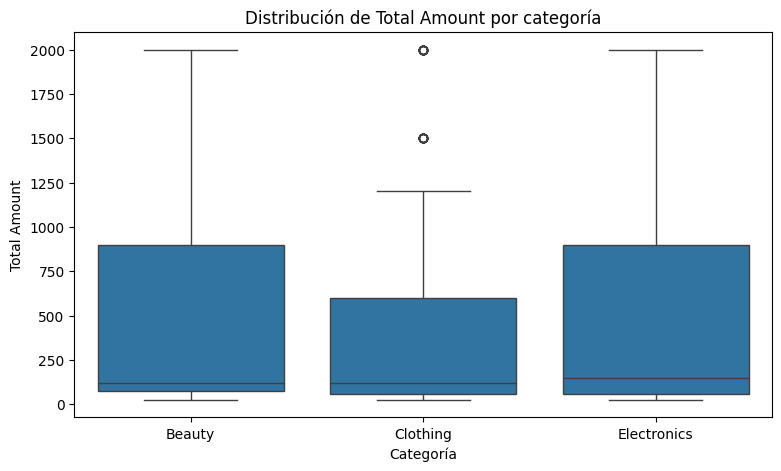

In [ ]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Product Category", y="Total Amount")
plt.title("Distribución de Total Amount por categoría")
plt.xlabel("Categoría")
plt.ylabel("Total Amount")
plt.show()

Dentro de **Clothing** sí aparecen 32 transacciones por encima de su límite (1.410), y se ven como puntos en el boxplot. En Beauty y Electronics no hay. Se examinan esos registros:

In [ ]:
clothing = df[df["Product Category"] == "Clothing"]

q1_clothing = clothing["Total Amount"].quantile(0.25)
q3_clothing = clothing["Total Amount"].quantile(0.75)
iqr_clothing = q3_clothing - q1_clothing
ls_clothing = q3_clothing + 1.5 * iqr_clothing

atipicos_clothing = clothing[clothing["Total Amount"] > ls_clothing]
print("Límite superior de Clothing:", ls_clothing)
print("Atípicos en Clothing:", len(atipicos_clothing))

Límite superior de Clothing: 1410.0
Atípicos en Clothing: 32


In [ ]:
atipicos_clothing[["Quantity", "Price per Unit", "Total Amount"]].value_counts()

,,,count
Quantity,Price per Unit,Total Amount,
4,500,2000,17
3,500,1500,15


In [ ]:
# ¿Cuántas compras de 1.500 o más hay en cada categoría?
compras_altas = df[df["Total Amount"] >= 1500]
compras_altas["Product Category"].value_counts()

,count
Product Category,
Beauty,34
Electronics,33
Clothing,32


### Análisis y decisión

- Los 32 "atípicos" de Clothing son compras de **3 × 500 = 1.500** (15) y **4 × 500 = 2.000** (17). Son valores totalmente coherentes con la fórmula del monto y con los precios del dataset.
- Además, Beauty (34) y Electronics (33) tienen **casi la misma cantidad** de compras de 1.500 o más que Clothing (32). La única razón por la que salen marcadas en Clothing es que su Q3 es más bajo (600 contra 900), lo que baja su límite superior. O sea, no es que Clothing tenga compras raras, sino que su caja quedó más corta.
- Por lo tanto, son **valores plausibles** y **no errores**.

**Decisión: se conservan todos los registros.** No hay atípicos con el criterio global, y los que aparecen al separar por categoría se explican por la forma de los datos y no por errores. Eliminarlos haría perder las compras de mayor valor, que son importantes para el total de ventas. Como se vio en los laboratorios, que un valor sea atípico no implica que haya que eliminarlo.

# 6. Relaciones, correlación y significancia estadística

## 6.1 Vista general: matrices de correlación

Antes de escoger una relación, se calcula la correlación entre todas las variables numéricas con Pearson y con Spearman, para tener un panorama general.

- **Pearson** mide qué tan fuerte es una relación **lineal**.
- **Spearman** trabaja con los rangos (posiciones) de los datos y mide si la relación es **monótona** (si cuando una sube la otra tiende a subir o a bajar, aunque no sea en línea recta). Es menos sensible a valores extremos y a distribuciones asimétricas.

In [ ]:
corr_pearson = df[variables].corr(method="pearson")
corr_pearson.round(3)

,Age,Quantity,Price per Unit,Total Amount
Age,1.000,-0.024,-0.038,-0.061
Quantity,-0.024,1.000,0.018,0.374
Price per Unit,-0.038,0.018,1.000,0.852
Total Amount,-0.061,0.374,0.852,1.000


In [ ]:
corr_spearman = df[variables].corr(method="spearman")
corr_spearman.round(3)

,Age,Quantity,Price per Unit,Total Amount
Age,1.000,-0.023,-0.038,-0.038
Quantity,-0.023,1.000,0.024,0.474
Price per Unit,-0.038,0.024,1.000,0.857
Total Amount,-0.038,0.474,0.857,1.000


Para ver la matriz más fácil se hace el mapa de calor de Pearson, como en el Laboratorio 7.1:

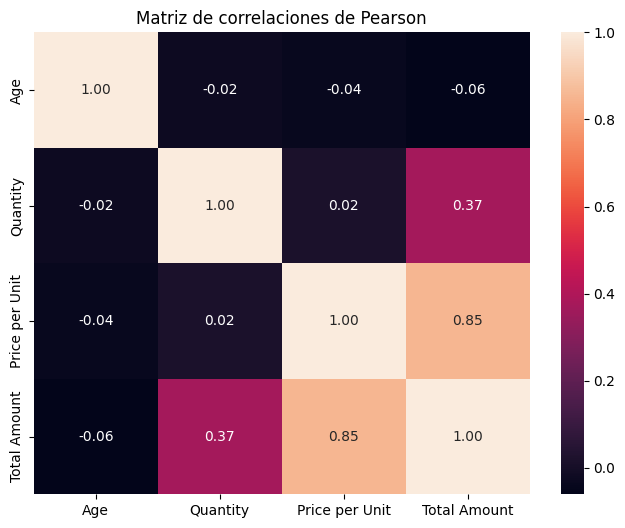

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f"
)
plt.title("Matriz de correlaciones de Pearson")
plt.show()

- Sin contar la diagonal (que siempre es 1 porque es cada variable consigo misma), la relación más fuerte es **`Price per Unit` ↔ `Total Amount`** (≈ 0,85 en ambos métodos).
- **`Quantity` ↔ `Total Amount`** es positiva pero moderada (0,374 con Pearson y 0,474 con Spearman).
- **`Age`** casi no se relaciona con nada (todos sus coeficientes están muy cerca de 0).
- `Quantity` y `Price per Unit` tampoco se relacionan entre sí (≈ 0,05): comprar un producto caro no hace que se compren más o menos unidades.

Con base en esto se estudian dos relaciones:

1. **Relación principal:** `Price per Unit` ↔ `Total Amount`.
2. **Relación complementaria:** `Age` ↔ `Total Amount`, para ver si la edad del cliente tiene que ver con cuánto gasta.

---

## 6.2 Relación principal: `Price per Unit` ↔ `Total Amount`

### Planteamiento

**Pregunta:** ¿las transacciones con productos de mayor precio por unidad tienen un monto total más alto?

Tiene sentido estudiarla porque el monto de la compra depende del precio, y sirve para entender qué tanto del valor de una venta se explica por el precio del producto, frente a la cantidad comprada.

### Gráfico de dispersión

Como `Price per Unit` solo tiene 5 valores y `Quantity` 4, solo existen 20 combinaciones posibles, así que muchos puntos quedan uno encima del otro. Por eso cada punto del gráfico puede representar varias transacciones.

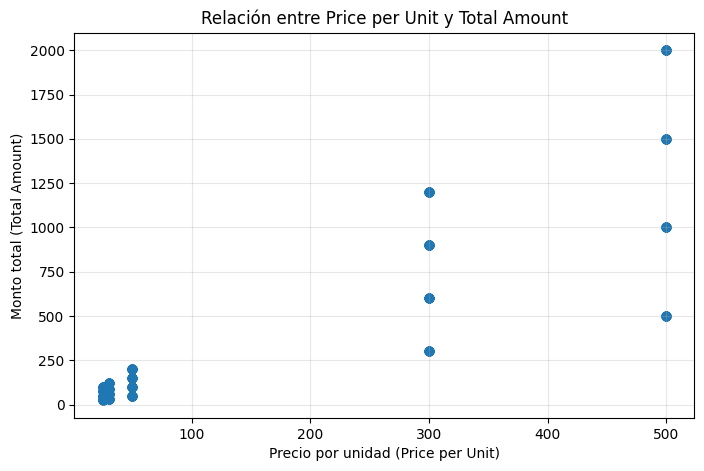

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Price per Unit"],
    df["Total Amount"],
    alpha=0.6
)
plt.xlabel("Precio por unidad (Price per Unit)")
plt.ylabel("Monto total (Total Amount)")
plt.title("Relación entre Price per Unit y Total Amount")
plt.grid(alpha=0.3)
plt.show()

Para ver mejor la tendencia, se calcula el monto promedio para cada precio:

In [ ]:
promedio_por_precio = df.groupby("Price per Unit")["Total Amount"].mean()
promedio_por_precio.round(2)

,Total Amount
Price per Unit,
25,62.14
30,72.95
50,126.54
300,788.83
500,1243.72


### Descripción del patrón

- **Dirección:** positiva. A mayor precio por unidad, mayor monto total.
- **Forma:** los puntos forman 5 columnas (una por precio). Dentro de cada columna hay 4 niveles, que son las cantidades de 1 a 4. Por eso el patrón tiene forma de **abanico**: con precios bajos los montos están muy juntos, y con precios altos se separan mucho más (con precio 500 el monto puede ir de 500 a 2.000).
- **Comportamiento:** en la tabla de promedios, el monto promedio es más o menos 2,5 veces el precio en cada nivel (62 para 25, 127 para 50, 789 para 300, 1.244 para 500; 2,5 es la cantidad promedio comprada). O sea, la tendencia central es **lineal**, aunque la dispersión aumenta con el precio.
- No hay puntos aislados que se salgan del patrón (coincide con que no hubo atípicos).

### Coeficientes de Pearson y Spearman

In [ ]:
pearson = df["Price per Unit"].corr(df["Total Amount"], method="pearson")
spearman = df["Price per Unit"].corr(df["Total Amount"], method="spearman")
print("Correlación de Pearson:", round(pearson, 4))
print("Correlación de Spearman:", round(spearman, 4))

Correlación de Pearson: 0.8519
Correlación de Spearman: 0.8574


### Interpretación y comparación

- **Signo:** los dos coeficientes son **positivos**, así que cuando sube el precio por unidad tiende a subir el monto total.
- **Magnitud:** Pearson da **0,852** y Spearman **0,857**. Los dos indican una relación **fuerte** (mayor a 0,7).
- **Comparación:** son casi iguales (diferencia de 0,005). Esto quiere decir que la relación es al mismo tiempo lineal y monótona, y que no hay valores extremos distorsionando a Pearson.

### ¿Cuál coeficiente representa mejor el patrón?

Se elige **Pearson**, por estas razones:

1. La tendencia es **lineal**: cada vez que el precio aumenta, el monto promedio aumenta en la misma proporción (tabla de promedios). Pearson es justamente la medida de relación lineal.
2. No hay valores atípicos (sección 5), que es la principal debilidad de Pearson.
3. Spearman da prácticamente el mismo resultado, lo que confirma que Pearson no está inflado ni afectado por la asimetría de `Total Amount`.

Spearman sería mejor si la relación fuera curva o si hubiera valores extremos, pero ese no es el caso aquí.

### Significancia estadística

Se plantea la prueba de hipótesis para la correlación de Pearson:

$$
H_0: \rho = 0 \quad \text{(no hay correlación entre el precio por unidad y el monto total)}
$$

$$
H_1: \rho \neq 0 \quad \text{(sí hay correlación)}
$$

con nivel de significancia $\alpha = 0.05$.

Es una prueba **bilateral**, porque $H_1$ dice "diferente de cero" (puede ser positiva o negativa).

**Regla de decisión:**

- Si $p\text{-value} \leq \alpha$, **se rechaza $H_0$**.
- Si $p\text{-value} > \alpha$, **no se rechaza $H_0$**.

Se usa `pearsonr()`, que devuelve el coeficiente $r$ y su p-value.

In [ ]:
r, p_value = pearsonr(
    df["Price per Unit"],
    df["Total Amount"]
)
alpha = 0.05
print("Coeficiente de Pearson:", round(r, 4))
print("p-value:", p_value)
print("Nivel de significancia:", alpha)
if p_value <= alpha:
    print("\nDecisión: Rechazar H0")
else:
    print("\nDecisión: No rechazar H0")

Coeficiente de Pearson: 0.8519
p-value: 1.22005244608631e-282
Nivel de significancia: 0.05

Decisión: Rechazar H0


### Interpretación del resultado

El p-value es aproximadamente $1.22 \times 10^{-282}$ (en la salida aparece como `1.22e-282`), un número prácticamente igual a cero y muchísimo menor que 0,05. Por lo tanto **se rechaza $H_0$** y la correlación es **estadísticamente significativa**.

El p-value indica qué tan probable sería encontrar una correlación tan fuerte como 0,852 si en realidad no existiera ninguna relación entre las variables. Como esa probabilidad es casi nula, se concluye que la relación **no es producto del azar**.

En palabras del negocio: en este dataset, **las transacciones de productos con mayor precio por unidad tienen montos totales significativamente más altos**, con una relación positiva, fuerte y lineal (r = 0,852; p < 0,05).

---

## 6.3 Relación complementaria: `Age` ↔ `Total Amount`

### Planteamiento

**Pregunta:** ¿los clientes de más edad gastan más (o menos) por transacción?

Es una pregunta típica en retail para decidir a qué público dirigir las campañas.

### Gráfico de dispersión

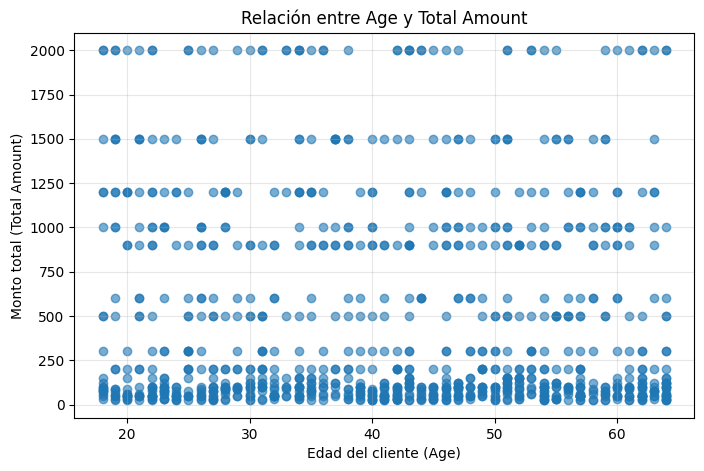

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Age"],
    df["Total Amount"],
    alpha=0.6
)
plt.xlabel("Edad del cliente (Age)")
plt.ylabel("Monto total (Total Amount)")
plt.title("Relación entre Age y Total Amount")
plt.grid(alpha=0.3)
plt.show()

**Patrón observado:** no se ve ninguna dirección. Los puntos forman franjas horizontales (los montos posibles) repartidas de forma pareja entre los 18 y los 64 años. Tanto los clientes jóvenes como los mayores hacen compras de 25 y de 2.000. No hay forma lineal ni curva.

### Coeficientes

In [ ]:
pearson_edad = df["Age"].corr(df["Total Amount"], method="pearson")
spearman_edad = df["Age"].corr(df["Total Amount"], method="spearman")
print("Correlación de Pearson:", round(pearson_edad, 4))
print("Correlación de Spearman:", round(spearman_edad, 4))

Correlación de Pearson: -0.0606
Correlación de Spearman: -0.0379


- Los dos coeficientes son **negativos pero casi cero** (−0,061 y −0,038): relación prácticamente **inexistente**.
- Aquí se escoge **Spearman**, porque el gráfico no muestra ninguna tendencia lineal que Pearson pueda describir, y `Total Amount` es muy asimétrica y con valores repetidos. Spearman, al trabajar con rangos, es más adecuado para ese tipo de datos.

### Prueba de hipótesis

$$
H_0: \rho = 0 \qquad H_1: \rho \neq 0 \qquad \alpha = 0.05
$$

Como se escogió Spearman, se usa `spearmanr()`, que funciona igual que `pearsonr()`: devuelve el coeficiente y su p-value. Para comparar, también se calcula el p-value de Pearson.

In [ ]:
rho_edad, p_edad = spearmanr(
    df["Age"],
    df["Total Amount"]
)
print("Coeficiente de Spearman:", round(rho_edad, 4))
print("p-value:", round(p_edad, 4))
print("Nivel de significancia:", alpha)
if p_edad <= alpha:
    print("\nDecisión: Rechazar H0")
else:
    print("\nDecisión: No rechazar H0")

Coeficiente de Spearman: -0.0379
p-value: 0.2316
Nivel de significancia: 0.05

Decisión: No rechazar H0


In [ ]:
r_edad, p_edad_pearson = pearsonr(
    df["Age"],
    df["Total Amount"]
)
print("Coeficiente de Pearson:", round(r_edad, 4))
print("p-value:", round(p_edad_pearson, 4))

Coeficiente de Pearson: -0.0606
p-value: 0.0555


### Interpretación

El p-value de Spearman es **0,23**, mayor que 0,05, así que **no se rechaza $H_0$**. No hay evidencia de que la edad del cliente se relacione con cuánto gasta por transacción.

Vale la pena notar que el p-value de Pearson (0,0555) quedó muy cerca de 0,05, pero **tampoco** es menor, así que la decisión es la misma con los dos métodos. Y aunque hubiera salido significativo, un r de −0,06 es tan pequeño que no tendría importancia práctica.

Importante: *no rechazar $H_0$* no es lo mismo que *demostrar* que la relación es cero. Solo significa que con estos datos no hay evidencia suficiente para decir que existe.

## 6.4 Visualización de las dos relaciones analizadas

Como en el Laboratorio 9, se grafican las dos relaciones con su línea de regresión, mostrando en el título el coeficiente y el p-value de cada una.

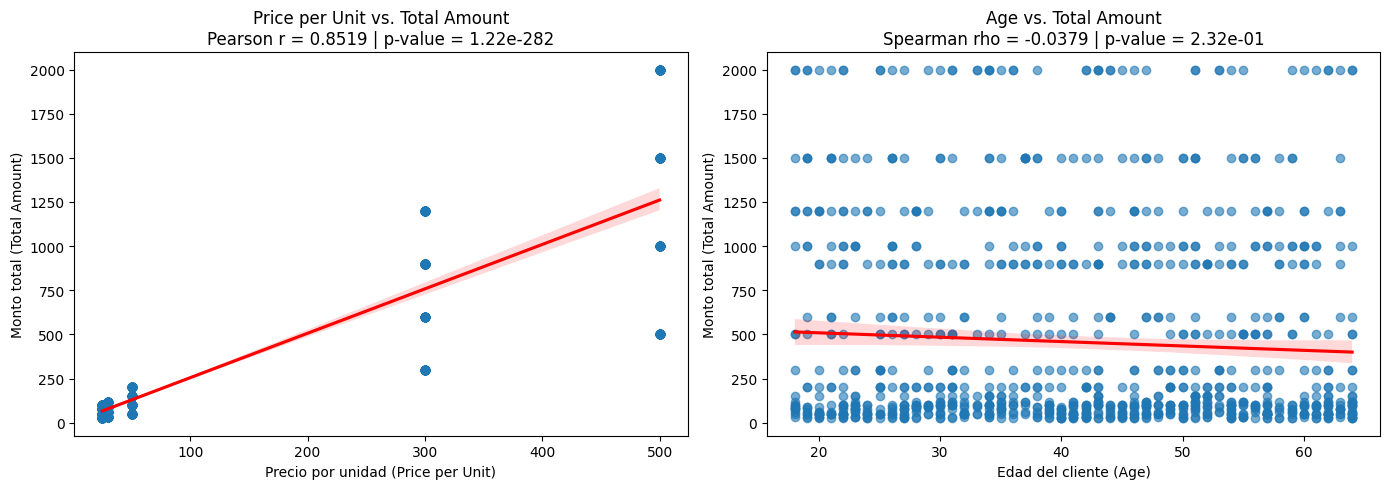

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(
    data=df,
    x="Price per Unit",
    y="Total Amount",
    ax=axes[0],
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)
axes[0].set_title(
    f"Price per Unit vs. Total Amount\nPearson r = {r:.4f} | p-value = {p_value:.2e}"
)
axes[0].set_xlabel("Precio por unidad (Price per Unit)")
axes[0].set_ylabel("Monto total (Total Amount)")

sns.regplot(
    data=df,
    x="Age",
    y="Total Amount",
    ax=axes[1],
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)
axes[1].set_title(
    f"Age vs. Total Amount\nSpearman rho = {rho_edad:.4f} | p-value = {p_edad:.2e}"
)
axes[1].set_xlabel("Edad del cliente (Age)")
axes[1].set_ylabel("Monto total (Total Amount)")

plt.tight_layout()
plt.show()

- En el gráfico de la izquierda la línea roja sube con bastante pendiente y los puntos siguen esa dirección: relación **positiva, fuerte y significativa**.
- En el de la derecha la línea es casi plana y los puntos están repartidos por todo el gráfico sin seguirla: **no hay relación** y el p-value es mayor que 0,05.
- Esto muestra la diferencia entre **intensidad** (qué tan grande es el coeficiente) y **significancia** (si hay evidencia de que la relación no es cero). En el primer caso se cumplen las dos; en el segundo, ninguna.

---

## 6.5 Correlación y causalidad

**¿La correlación entre `Price per Unit` y `Total Amount` demuestra que el precio causa el monto?**

**No, la correlación por sí sola no demuestra causalidad.** El coeficiente de Pearson solo dice que las dos variables se mueven juntas de forma lineal. No dice por qué.

En este caso particular sí sabemos que el precio influye en el monto, pero eso **no lo sabemos por la correlación**, sino por la definición de la variable: en la sección 2 se verificó que `Total Amount = Quantity × Price per Unit`. Es una relación matemática de cómo se construye el dato, no algo que haya descubierto el análisis estadístico.

Además, hay que tener cuidado con la conclusión de negocio: que haya correlación no significa que **subir los precios** vaya a aumentar las ventas. Con precios más altos los clientes podrían comprar menos unidades o no comprar. Para afirmar algo así se necesitaría un experimento o datos de qué pasa cuando cambian los precios, y este dataset solo registra transacciones que ya ocurrieron (y además es sintético).

En la relación `Age` ↔ `Total Amount` ni siquiera hay correlación significativa, así que tampoco se puede hablar de causalidad.

# 7. Conclusiones

1. **Calidad de los datos.** El dataset tiene 1.000 transacciones y 9 variables, sin valores faltantes, sin duplicados y sin categorías mal escritas. El monto total coincide con cantidad × precio en todas las filas. Solo fue necesario corregir tipos de dato: `Date` pasó a fecha y `Transaction ID` a texto por ser un identificador. Las 2 transacciones de enero de 2024 se conservaron porque son válidas.

2. **Valor típico de una compra.** `Total Amount` tiene una media de 456 pero una mediana de 135, con una desviación estándar (560) mayor que la media. La distribución es asimétrica a la derecha: hay muchas compras pequeñas y un grupo de compras grandes (hasta 2.000). Por eso la **mediana** describe mejor una compra típica. El 50 % central de las compras está entre 60 y 900 (IQR = 840).

3. **Grupos.** Las diferencias entre categorías son pequeñas: Electronics vende un poco más en total (156.905), Clothing tiene más transacciones (351) y Beauty tiene el mayor promedio por compra (467,48). Entre hombres y mujeres el gasto promedio es casi idéntico (≈ 456). Por mes, las ventas varían sin una tendencia clara; mayo fue el mejor mes y septiembre el más bajo.

4. **Valores atípicos.** Con el criterio IQR global no hay atípicos en ninguna variable (límite superior de `Total Amount` = 2.160 y máximo = 2.000). Al separar por categoría aparecen 32 en Clothing, pero son compras de 1.500 y 2.000 perfectamente coherentes (3 o 4 unidades de 500), igual de frecuentes que en las otras categorías. Se decidió **conservarlas todas**.

5. **Relaciones.** El precio por unidad tiene una relación **positiva, fuerte y lineal** con el monto total (Pearson r = 0,852, Spearman ρ = 0,857). Se eligió Pearson porque la tendencia es lineal y no hay atípicos. La correlación es **estadísticamente significativa** (p ≈ 0 < 0,05, se rechaza $H_0$). En cambio, la edad del cliente **no se relaciona** con el monto (Spearman ρ = −0,038, p = 0,23, no se rechaza $H_0$). La cantidad de unidades tiene una relación positiva pero solo moderada con el monto. En resumen, **el valor de una venta depende sobre todo del precio del producto**, más que de la cantidad, y no depende de la edad ni del género del cliente.

6. **Causalidad.** La correlación no demuestra causalidad. Sabemos que el precio forma parte del monto por cómo se calcula la variable, no por la correlación; y de ella tampoco se puede concluir que subir precios aumente las ventas.

7. **Limitación.** El dataset es sintético: por ejemplo, las tres categorías tienen exactamente los mismos cinco precios y cada cliente compra una sola vez. Por eso los resultados sirven para practicar el proceso de análisis, pero no para sacar conclusiones sobre un negocio real.